# Trabajo práctico 4


## Importar dataset de roboflow

In [ ]:
!pip install -q roboflow ultralytics

import os
from getpass import getpass
from roboflow import Roboflow

ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY")

if not ROBOFLOW_API_KEY:
    try:
        from google.colab import userdata
        ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        pass

if not ROBOFLOW_API_KEY:
    ROBOFLOW_API_KEY = getpass("Ingresá tu Roboflow API key: ")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("pavlo-mukalov-ir2ac").project("military_aero")
version = project.version(2)
dataset = version.download("yolov8")

dataset_base_path = dataset.location
print("Dataset descargado en:", dataset_base_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.8 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to military_aero-2 in yolov8:: 100%|██████████| 12638/12638 [00:02<00:00, 5812.43it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dataset descargado en: /content/military_aero-2


## Análisis de dataset


--- Training Images ---


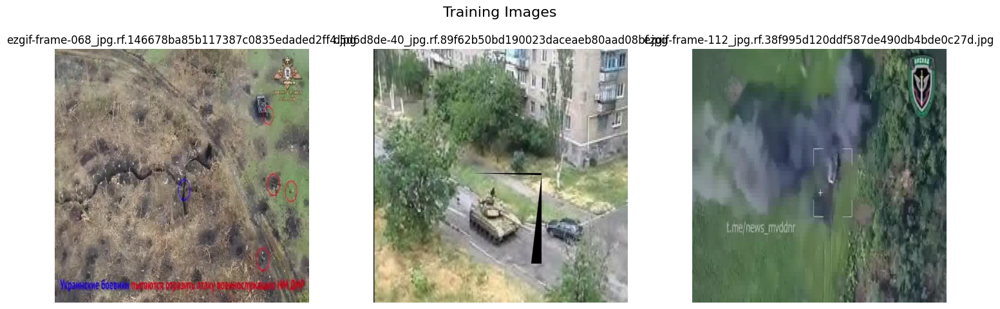


--- Validation Images ---


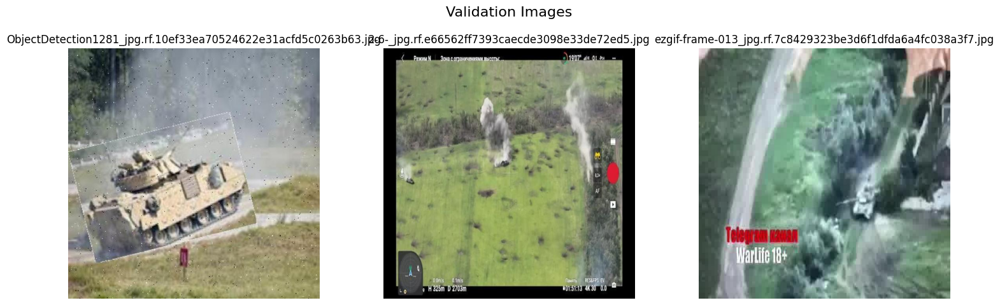


--- Test Images ---


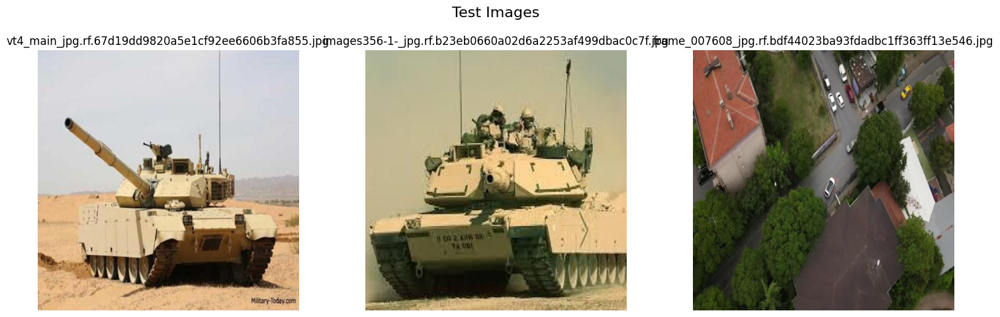

Cantidad de muestras: 6313


In [ ]:
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt

# Function to display sample images from a given path
def display_sample_images(image_dir, title, num_images=3):
    image_paths = glob.glob(os.path.join(image_dir, '*.jpg')) # Assuming JPG images
    if not image_paths:
        image_paths = glob.glob(os.path.join(image_dir, '*.png')) # Check for PNG if no JPG

    if not image_paths:
        print(f"No images found in {image_dir}")
        return

    print(f"\n--- {title} ---")
    plt.figure(figsize=(15, 5))
    for i, img_path in enumerate(image_paths[:num_images]):
        img = Image.open(img_path)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(img_path))
        plt.axis('off')
    plt.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
    plt.show()

# Display images from the 'train' set
train_images_dir = os.path.join(dataset_base_path, 'train', 'images')
display_sample_images(train_images_dir, 'Training Images')

# Display images from the 'valid' set
valid_images_dir = os.path.join(dataset_base_path, 'valid', 'images')
display_sample_images(valid_images_dir, 'Validation Images')

# Display images from the 'test' set
test_images_dir = os.path.join(dataset_base_path, 'test', 'images')
display_sample_images(test_images_dir, 'Test Images')

def list_images(image_dir):
    """Devuelve las rutas (ordenadas) de todas las imágenes de un directorio."""
    paths = []
    for ext in ('*.jpg', '*.jpeg', '*.png'):
        paths.extend(glob.glob(os.path.join(image_dir, ext)))
    return sorted(paths)

n_muestras = sum(len(list_images(d)) for d in (train_images_dir, valid_images_dir, test_images_dir))
print(f"Cantidad de muestras: {n_muestras}")

## Labels disponible

In [ ]:
import yaml
import os
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the data.yaml file
data_yaml_path = os.path.join(dataset_base_path, 'data.yaml')

# Load the data.yaml file to get class names
with open(data_yaml_path, 'r') as f:
    data_yaml = yaml.safe_load(f)

class_names = data_yaml['names']
print("Class Names (Labels):", class_names)
print(f"Number of classes: {len(class_names)}")

Class Names (Labels): ['Airplane', 'Armored_car', 'BMP', 'Car', 'Person', 'Plane', 'RSZO', 'Sau', 'Tank', 'Truck']
Number of classes: 10


### Distribución de las labels

In [ ]:
import pandas as pd


def count_labels_in_split(labels_dir, class_names):
    """Cuenta, para cada clase, la cantidad de instancias (bounding boxes) y la cantidad
    de imágenes que contienen al menos una instancia de esa clase."""
    label_counts = Counter()
    image_counts = Counter()
    annotation_files = glob.glob(os.path.join(labels_dir, '*.txt'))

    for anno_file in annotation_files:
        classes_in_image = set()
        with open(anno_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    class_id = int(parts[0])
                    if 0 <= class_id < len(class_names):
                        label_counts[class_names[class_id]] += 1
                        classes_in_image.add(class_names[class_id])
        image_counts.update(classes_in_image)
    return label_counts, image_counts


def distribution_table(label_counts, image_counts):
    """Tabla con instancias e imágenes por clase, ordenada por cantidad de instancias."""
    df = pd.DataFrame({'Instancias': pd.Series(label_counts), 'Imágenes': pd.Series(image_counts)})
    return df.fillna(0).astype(int).sort_values('Instancias', ascending=False)


# Directories for labels
train_labels_dir = os.path.join(dataset_base_path, 'train', 'labels')
valid_labels_dir = os.path.join(dataset_base_path, 'valid', 'labels')
test_labels_dir = os.path.join(dataset_base_path, 'test', 'labels')

# Count labels for each split
train_label_counts, train_image_counts = count_labels_in_split(train_labels_dir, class_names)
valid_label_counts, valid_image_counts = count_labels_in_split(valid_labels_dir, class_names)
test_label_counts, test_image_counts = count_labels_in_split(test_labels_dir, class_names)

print("\n--- Label Distribution in Training Set (Sorted) ---")
display(distribution_table(train_label_counts, train_image_counts))

print("\n--- Label Distribution in Validation Set (Sorted) ---")
display(distribution_table(valid_label_counts, valid_image_counts))

print("\n--- Label Distribution in Test Set (Sorted) ---")
display(distribution_table(test_label_counts, test_image_counts))


--- Label Distribution in Training Set (Sorted) ---


,Instancias,Imágenes
Person,5647,1530
Tank,4714,3186
Airplane,3241,243
Car,2332,489
RSZO,338,231
Armored_car,162,118
Sau,129,62
Truck,118,66
Plane,117,77
BMP,64,46



--- Label Distribution in Validation Set (Sorted) ---


,Instancias,Imágenes
Person,952,283
Tank,888,589
Airplane,873,63
Car,259,69
Plane,34,21
Armored_car,34,24
RSZO,33,24
Sau,17,9
Truck,17,5
BMP,10,5



--- Label Distribution in Test Set (Sorted) ---


,Instancias,Imágenes
Person,608,146
Tank,474,323
Car,454,59
Airplane,70,4
RSZO,28,20
Truck,27,6
Sau,21,9
Plane,19,10
Armored_car,16,11
BMP,6,6


### Visualización de la distribución de etiquetas

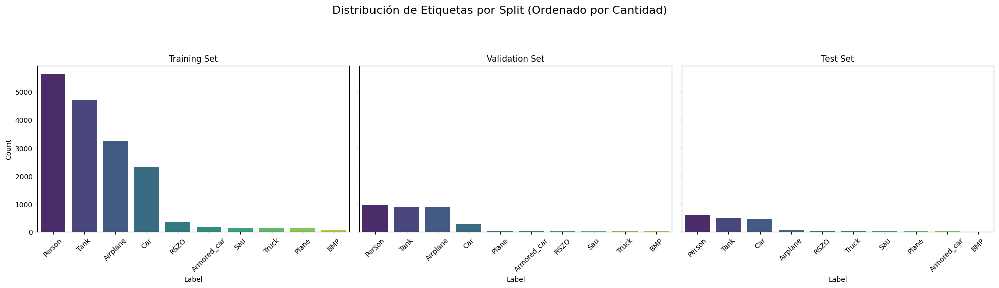

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare dataframes for each split and sort them by count in descending order
train_df = pd.DataFrame(train_label_counts.items(), columns=['Label', 'Count']).sort_values('Count', ascending=False)
valid_df = pd.DataFrame(valid_label_counts.items(), columns=['Label', 'Count']).sort_values('Count', ascending=False)
test_df = pd.DataFrame(test_label_counts.items(), columns=['Label', 'Count']).sort_values('Count', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
fig.suptitle('Distribución de Etiquetas por Split (Ordenado por Cantidad)', fontsize=16)

# Plot Training Set
sns.barplot(x='Label', y='Count', data=train_df, ax=axes[0], palette='viridis', hue='Label', legend=False)
axes[0].set_title('Training Set')
axes[0].tick_params(axis='x', rotation=45)

# Plot Validation Set
sns.barplot(x='Label', y='Count', data=valid_df, ax=axes[1], palette='viridis', hue='Label', legend=False)
axes[1].set_title('Validation Set')
axes[1].tick_params(axis='x', rotation=45)

# Plot Test Set
sns.barplot(x='Label', y='Count', data=test_df, ax=axes[2], palette='viridis', hue='Label', legend=False)
axes[2].set_title('Test Set')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0.03, 1, 0.9])
plt.show()

### Ejemplos de imágenes por clase

Para cada clase del dataset mostramos un conjunto de imágenes de train que contienen al menos una instancia de esa clase. En cada fila se dibujan solo las cajas (ground truth) de la clase correspondiente.

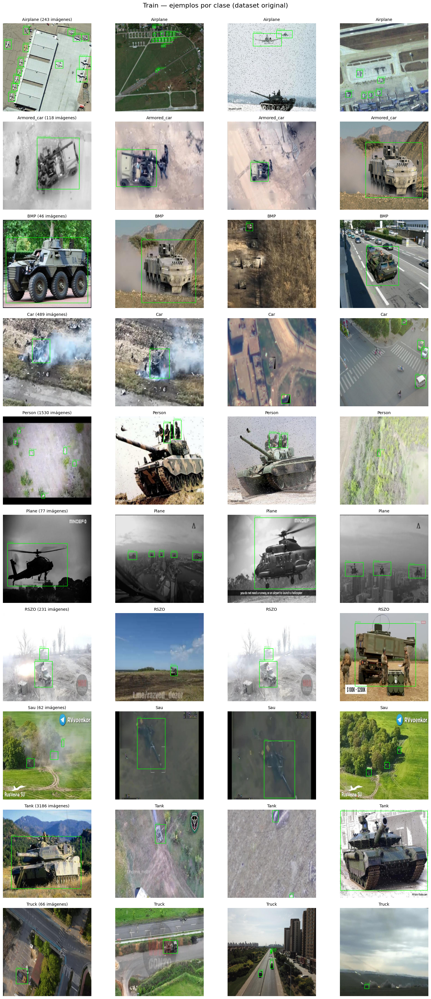

In [ ]:
import random
import cv2
import numpy as np


def yolo_to_xyxy(class_id, xc, yc, w, h, img_w, img_h):
    """Convierte una caja en formato YOLO (normalizado) a coordenadas de píxel (x1, y1, x2, y2)."""
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return int(class_id), x1, y1, x2, y2


def label_path_for(img_path, labels_dir):
    return os.path.join(labels_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')


def draw_boxes_on_image(image_path, label_path, class_names, color=(0, 255, 0), only_class=None):
    """Dibuja las anotaciones (ground truth) de un archivo de labels YOLO sobre la imagen.
    Si se pasa `only_class`, solo se dibujan las cajas de esa clase."""
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                cls_id, x1, y1, x2, y2 = yolo_to_xyxy(*[float(p) for p in parts], w, h)
                if only_class is not None and cls_id != only_class:
                    continue
                cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
                label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
                cv2.putText(img, label, (int(x1), max(int(y1) - 5, 0)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    return img


def index_images_by_class(images_dir, labels_dir, n_classes):
    """Devuelve {class_id: [imágenes que contienen al menos una instancia de esa clase]}."""
    images_by_class = {i: [] for i in range(n_classes)}
    for img_path in list_images(images_dir):
        label_path = label_path_for(img_path, labels_dir)
        if not os.path.exists(label_path):
            continue
        with open(label_path, 'r') as f:
            ids = {int(line.split()[0]) for line in f if line.strip()}
        for cls_id in ids:
            if cls_id in images_by_class:
                images_by_class[cls_id].append(img_path)
    return images_by_class


def show_samples_per_class(images_dir, labels_dir, class_names, title, num_per_class=4, seed=42):
    """Muestra una fila por clase con `num_per_class` imágenes que contienen esa clase."""
    images_by_class = index_images_by_class(images_dir, labels_dir, len(class_names))
    rng = random.Random(seed)
    fig, axes = plt.subplots(len(class_names), num_per_class,
                             figsize=(4 * num_per_class, 3.5 * len(class_names)), squeeze=False)
    for cls_id, name in enumerate(class_names):
        paths = images_by_class[cls_id]
        chosen = rng.sample(paths, min(num_per_class, len(paths)))
        for j in range(num_per_class):
            ax = axes[cls_id, j]
            ax.axis('off')
            if j >= len(chosen):
                if j == 0:
                    ax.set_title(f'{name} (sin imágenes)', fontsize=10)
                continue
            img = draw_boxes_on_image(chosen[j], label_path_for(chosen[j], labels_dir),
                                      class_names, only_class=cls_id)
            ax.imshow(img)
            ax.set_title(f'{name} ({len(paths)} imágenes)' if j == 0 else name, fontsize=10)
    fig.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


show_samples_per_class(train_images_dir, train_labels_dir, class_names,
                       'Train — ejemplos por clase (dataset original)')

## Selección de clases objetivo (filtrado del dataset)


El dataset original tiene 10 clases, pero solo nos interesan **Person, Car, Airplane y Tank**. En vez de entrenar dejando la cabeza del modelo con las 10 clases y filtrar solo con el parámetro `classes=[...]` en tiempo de entrenamiento (lo que deja al modelo con salidas para clases que nunca vamos a usar), construimos un dataset nuevo con:

- Solo las etiquetas de las 4 clases objetivo, **remapeadas a IDs `0..3`**.
- Un `data.yaml` nuevo con `nc: 4`.
- Se descartan las imágenes que **no** contienen ninguna instancia de estas 4 clases (si una imagen solo tenía, por ejemplo, un `BMP` y ningún objeto de nuestras clases, no aporta señal de entrenamiento útil para este problema).

In [ ]:
import shutil

target_classes = ['Person', 'Car', 'Airplane', 'Tank']
old_id_to_new_id = {class_names.index(name): i for i, name in enumerate(target_classes)}

filtered_base = '/content/military_aero_filtered'
splits = ['train', 'valid', 'test']

for split in splits:
    src_img_dir = os.path.join(dataset_base_path, split, 'images')
    src_lbl_dir = os.path.join(dataset_base_path, split, 'labels')
    dst_img_dir = os.path.join(filtered_base, split, 'images')
    dst_lbl_dir = os.path.join(filtered_base, split, 'labels')
    os.makedirs(dst_img_dir, exist_ok=True)
    os.makedirs(dst_lbl_dir, exist_ok=True)

    for lbl_path in glob.glob(os.path.join(src_lbl_dir, '*.txt')):
        new_lines = []
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                old_cls = int(parts[0])
                if old_cls in old_id_to_new_id:
                    new_lines.append(' '.join([str(old_id_to_new_id[old_cls])] + parts[1:]))

        if not new_lines:
            continue  # esta imagen no tiene ninguna de las 4 clases objetivo

        base_name = os.path.splitext(os.path.basename(lbl_path))[0]
        with open(os.path.join(dst_lbl_dir, base_name + '.txt'), 'w') as f:
            f.write('\n'.join(new_lines))

        for ext in ('.jpg', '.jpeg', '.png'):
            src_img = os.path.join(src_img_dir, base_name + ext)
            if os.path.exists(src_img):
                shutil.copy(src_img, os.path.join(dst_img_dir, base_name + ext))
                break

filtered_data_yaml = {
    'train': os.path.join(filtered_base, 'train', 'images'),
    'val': os.path.join(filtered_base, 'valid', 'images'),
    'test': os.path.join(filtered_base, 'test', 'images'),
    'nc': len(target_classes),
    'names': target_classes,
}
filtered_yaml_path = os.path.join(filtered_base, 'data.yaml')
with open(filtered_yaml_path, 'w') as f:
    yaml.dump(filtered_data_yaml, f)

print(f"Dataset filtrado creado en: {filtered_base}")
print(f"data.yaml filtrado: {filtered_yaml_path}")

Dataset filtrado creado en: /content/military_aero_filtered
data.yaml filtrado: /content/military_aero_filtered/data.yaml


In [ ]:
print("Cantidad de imágenes por split (dataset filtrado a 4 clases):\n")
total = 0
for key in ['train', 'valid', 'test']:
    n_imgs = len(glob.glob(os.path.join(filtered_base, key, 'images', '*')))
    total += n_imgs
    print(f"  {key:6s}: {n_imgs} imágenes")
print(f"\nTotal: {total} imágenes")
print(
    "\nLa división train/valid/test viene heredada del dataset original de "
    "Roboflow; acá solo se filtran las clases y se descartan imágenes sin "
    "objetos de interés, no se vuelve a mezclar ni resplitea."
)

Cantidad de imágenes por split (dataset filtrado a 4 clases):

  train : 4556 imágenes
  valid : 847 imágenes
  test  : 413 imágenes

Total: 5816 imágenes

La división train/valid/test viene heredada del dataset original de Roboflow; acá solo se filtran las clases y se descartan imágenes sin objetos de interés, no se vuelve a mezclar ni resplitea.


## Preprocesamiento


Pasos de preprocesamiento aplicados:

- **Redimensionamiento**: todas las imágenes se llevan al tamaño de entrada del modelo (`imgsz`) antes de pasar por la red.
- **Normalización**: Ultralytics normaliza automáticamente los píxeles al rango `[0, 1]` antes de alimentar la red.
- **Data augmentation**: `Blur`, `MedianBlur`, `ToGray`, `CLAHE`, flip horizontal, mosaic, y jitter de HSV.

Primero visualizamos imágenes del dataset filtrado, **un conjunto por clase**, junto con sus **anotaciones (bounding boxes)**.

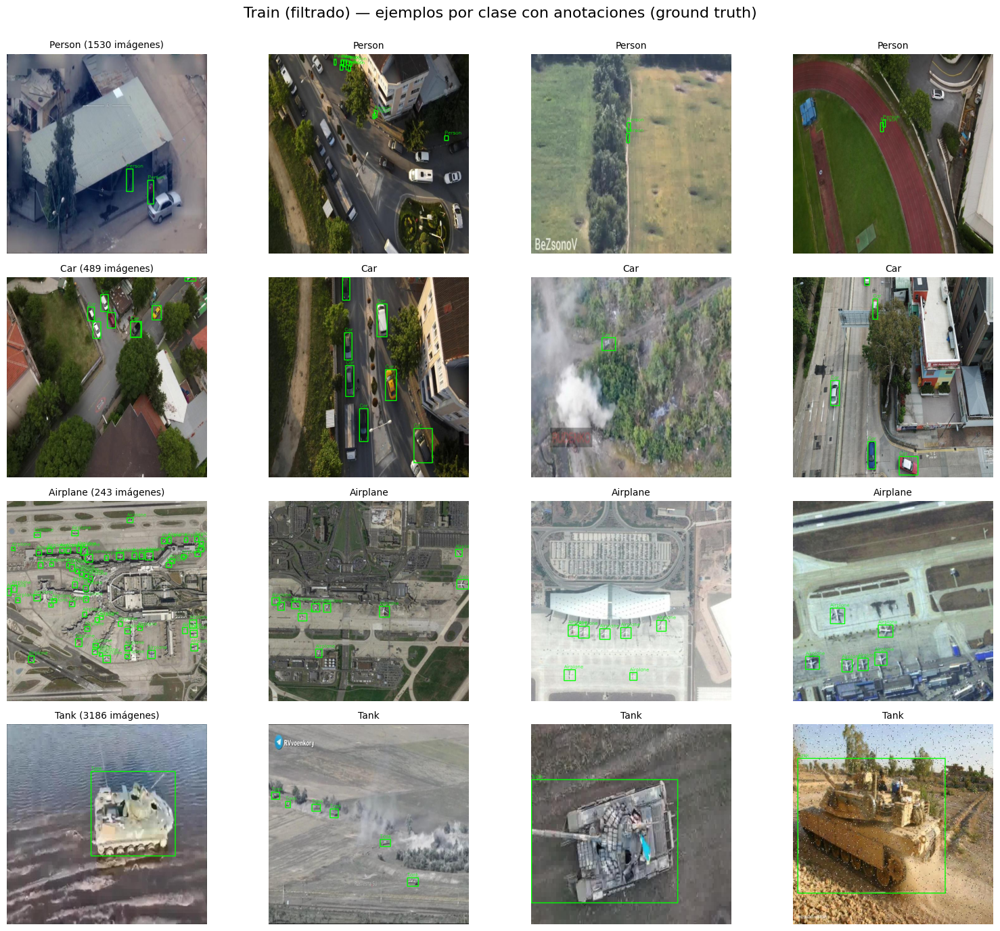

In [ ]:
filtered_train_images_dir = os.path.join(filtered_base, 'train', 'images')
filtered_train_labels_dir = os.path.join(filtered_base, 'train', 'labels')

show_samples_per_class(filtered_train_images_dir, filtered_train_labels_dir, target_classes,
                       'Train (filtrado) — ejemplos por clase con anotaciones (ground truth)')

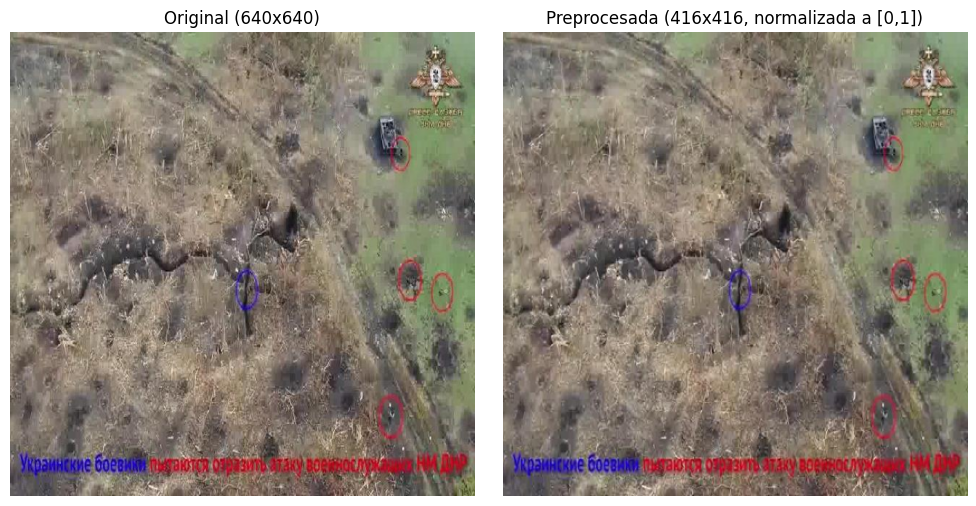

In [ ]:
sample_img_path = glob.glob(os.path.join(filtered_train_images_dir, '*.jpg'))[0]
img_orig = Image.open(sample_img_path)
IMG_SIZE_DEMO = 416
img_resized = img_orig.resize((IMG_SIZE_DEMO, IMG_SIZE_DEMO))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_orig)
axes[0].set_title(f'Original ({img_orig.size[0]}x{img_orig.size[1]})')
axes[0].axis('off')
axes[1].imshow(img_resized)
axes[1].set_title(f'Preprocesada ({IMG_SIZE_DEMO}x{IMG_SIZE_DEMO}, normalizada a [0,1])')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## Entrenamiento de modelo

In [ ]:
from ultralytics import YOLO
import pandas as pd
import torch

# Modelo y dataset ya filtrado (nc=4, sin las 6 clases que no usamos).
MODEL_SIZE = 'yolov8n.pt'
EPOCHS = 30
IMG_SIZE = 416
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
BATCH = 16 if torch.cuda.is_available() else 4

print(f"Entrenando {MODEL_SIZE} en device={DEVICE}, {EPOCHS} épocas, imgsz={IMG_SIZE}, batch={BATCH}")
print(f"Clases objetivo: {target_classes}")

model = YOLO(MODEL_SIZE)

# results.csv de Ultralytics solo guarda el mAP promediado entre clases, así que
# registramos el AP50 y AP50-95 de cada clase al final de cada época con un callback.
per_class_map_history = []

def log_per_class_map(trainer):
    validator = trainer.validator
    # on_fit_epoch_end también se dispara en la validación final con best.pt (fuera del loop): la salteamos
    if validator is None or not getattr(validator, 'training', False):
        return
    try:
        box = validator.metrics.box
        row = {'epoch': trainer.epoch + 1}
        for j, cls_idx in enumerate(box.ap_class_index):
            name = target_classes[int(cls_idx)]
            row[f'{name}/AP50'] = float(box.ap50[j])
            row[f'{name}/AP50-95'] = float(box.ap[j])
        per_class_map_history.append(row)
    except Exception as e:  # un problema de logging no debería cortar el entrenamiento
        print(f"[log_per_class_map] no se pudo registrar el mAP por clase: {e}")

model.add_callback('on_fit_epoch_end', log_per_class_map)

results = model.train(
    data=filtered_yaml_path,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=DEVICE,
    seed=42,
    patience=15,        # early stopping si no mejora en 15 épocas
    name='yolo_deteccion_tp4',
    project='/content/runs/detect',
)

run_dir = str(results.save_dir)
pd.DataFrame(per_class_map_history).to_csv(os.path.join(run_dir, 'per_class_map.csv'), index=False)
print("Resultados guardados en:", run_dir)

Entrenando yolov8n.pt en device=0, 30 épocas, imgsz=416, batch=16
Clases objetivo: ['Person', 'Car', 'Airplane', 'Tank']
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/military_aero_filtered/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

### Visualización de Resultados del Entrenamiento

Una vez finalizado el entrenamiento, visualizamos las gráficas de pérdida (Loss) y de mAP global que Ultralytics guarda en `results.csv`, y además el **AP de cada clase por época** (registrado con el callback del entrenamiento), para ver cómo evoluciona el desempeño de cada clase por separado.

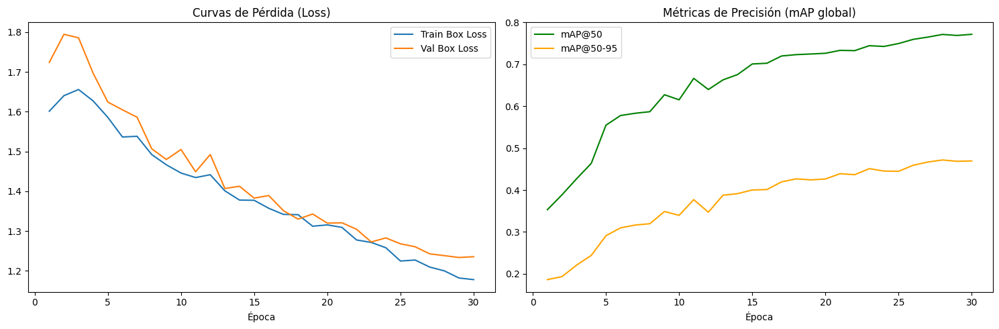

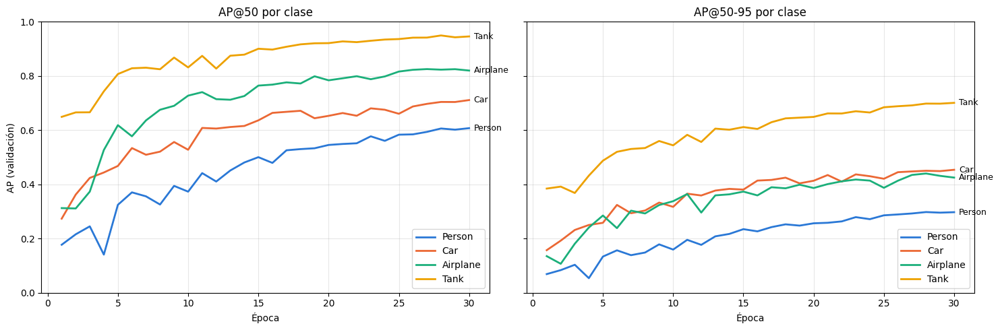

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Un color fijo por clase, usado en todos los gráficos por clase
CLASS_COLORS = dict(zip(target_classes, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))

results_path = os.path.join(run_dir, 'results.csv')
per_class_path = os.path.join(run_dir, 'per_class_map.csv')

if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
    results_df.columns = [c.strip() for c in results_df.columns]

    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    # Curvas de Loss
    if 'train/box_loss' in results_df.columns:
        ax[0].plot(results_df['epoch'], results_df['train/box_loss'], label='Train Box Loss')
        ax[0].plot(results_df['epoch'], results_df['val/box_loss'], label='Val Box Loss')
        ax[0].set_xlabel('Época')
        ax[0].set_title('Curvas de Pérdida (Loss)')
        ax[0].legend()

    # Curvas de mAP global (promedio entre clases)
    if 'metrics/mAP50(B)' in results_df.columns:
        ax[1].plot(results_df['epoch'], results_df['metrics/mAP50(B)'], label='mAP@50', color='green')
        ax[1].plot(results_df['epoch'], results_df['metrics/mAP50-95(B)'], label='mAP@50-95', color='orange')
        ax[1].set_xlabel('Época')
        ax[1].set_title('Métricas de Precisión (mAP global)')
        ax[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print(f"El archivo {results_path} no existe todavía. Esperá a que termine el entrenamiento.")

# Curvas de AP por clase
if os.path.exists(per_class_path) and os.path.getsize(per_class_path) > 1:
    per_class_map_df = pd.read_csv(per_class_path)

    fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for k, (metric, title) in enumerate([('AP50', 'AP@50 por clase'), ('AP50-95', 'AP@50-95 por clase')]):
        for name in target_classes:
            col = f'{name}/{metric}'
            if col not in per_class_map_df.columns:
                continue
            ax[k].plot(per_class_map_df['epoch'], per_class_map_df[col], label=name,
                       color=CLASS_COLORS[name], linewidth=2)
            # etiqueta directa al final de cada curva
            ax[k].annotate(name, (per_class_map_df['epoch'].iloc[-1], per_class_map_df[col].iloc[-1]),
                           xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)
        ax[k].set_title(title)
        ax[k].set_xlabel('Época')
        ax[k].set_ylim(0, 1)
        ax[k].grid(alpha=0.3)
        ax[k].legend(loc='lower right')
    ax[0].set_ylabel('AP (validación)')
    plt.tight_layout()
    plt.show()
else:
    print(f"No se encontró {per_class_path}: volvé a correr el entrenamiento (incluye el callback de mAP por clase).")

### Evaluación Final en el Split de Validación

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2132.0±899.0 MB/s, size: 64.5 KB)
val: Scanning /content/military_aero_filtered/valid/labels.cache... 847 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 847/847 296.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 6.0it/s 8.8s
                   all        847       2972      0.846      0.697      0.772      0.472
                Person        283        952      0.742      0.546      0.608      0.298
                   Car         69        259      0.835      0.633      0.707      0.452
              Airplane         63        873      0.892      0.696      0.824       0.44
                  Tank        589        888      0.916      0.911       0.95      0.698
Speed: 0.8ms preprocess, 2.4ms i

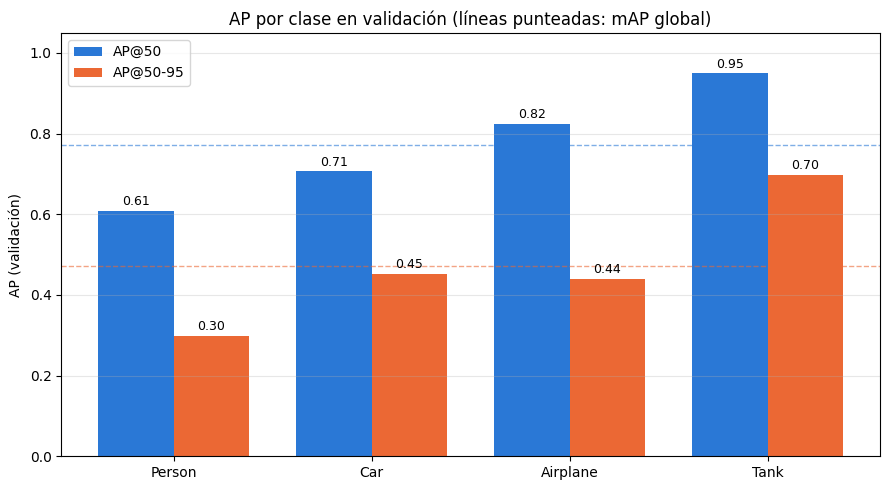

In [ ]:
from ultralytics import YOLO
import os

best_model_path = os.path.join(run_dir, 'weights', 'best.pt')
model_eval = YOLO(best_model_path)

val_metrics = model_eval.val(data=filtered_yaml_path, split='val')

print(f"Precisión media (P):     {val_metrics.box.mp:.4f}")
print(f"Recall medio (R):        {val_metrics.box.mr:.4f}")
print(f"mAP@50:                  {val_metrics.box.map50:.4f}")
print(f"mAP@50-95:               {val_metrics.box.map:.4f}")

print("\nPor clase:")
for i, name in enumerate(target_classes):
    print(f"  {name}: AP50={val_metrics.box.ap50[i]:.4f}, AP50-95={val_metrics.box.ap[i]:.4f}")

# AP final por clase (best.pt sobre validación)
x = np.arange(len(target_classes))
width = 0.38
ap50_vals = [val_metrics.box.ap50[i] for i in range(len(target_classes))]
ap_vals = [val_metrics.box.ap[i] for i in range(len(target_classes))]

fig, ax = plt.subplots(figsize=(9, 5))
bars50 = ax.bar(x - width / 2, ap50_vals, width, label='AP@50', color='#2a78d6')
bars = ax.bar(x + width / 2, ap_vals, width, label='AP@50-95', color='#eb6834')
ax.bar_label(bars50, fmt='%.2f', padding=2, fontsize=9)
ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=9)
ax.axhline(val_metrics.box.map50, color='#2a78d6', linestyle='--', linewidth=1, alpha=0.6)
ax.axhline(val_metrics.box.map, color='#eb6834', linestyle='--', linewidth=1, alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(target_classes)
ax.set_ylim(0, 1.05)
ax.set_ylabel('AP (validación)')
ax.set_title('AP por clase en validación (líneas punteadas: mAP global)')
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Evaluación y resultados en el set de Test



Con el modelo ya entrenado (`best.pt`), corremos inferencia sobre imágenes nunca vistas (split de test) y comparamos visualmente la predicción contra la anotación real (ground truth).

In [ ]:
test_images_dir_f = os.path.join(filtered_base, 'test', 'images')
test_labels_dir_f = os.path.join(filtered_base, 'test', 'labels')
test_image_paths = list_images(test_images_dir_f)

CONF_THRESHOLD = 0.25

# Predicción en batch sobre todo el set de test (se reutiliza para IoU/Dice y para los ejemplos visuales)
all_predictions = model_eval.predict(test_image_paths, conf=CONF_THRESHOLD, verbose=False)
print(f"Predicciones sobre {len(test_image_paths)} imágenes de test (conf >= {CONF_THRESHOLD})")

Predicciones sobre 413 imágenes de test (conf >= 0.25)


### Métricas de solapamiento: IoU y Dice


Además de precisión/recall/mAP, calculamos manualmente el **IoU (Intersection over Union)** y el **coeficiente de Dice** entre cada predicción y su anotación real, para tener una medida directa de qué tan bien se superponen las cajas predichas con las reales (no solo si "acertó la clase", sino cuán ajustada está la caja).

- **IoU** = área de intersección / área de unión entre la caja predicha y la real.
- **Dice** = 2·IoU / (1 + IoU) — es el coeficiente de Dice expresado en función del IoU (equivalente al usado en segmentación, aplicado acá a bounding boxes).

Para cada predicción, la emparejamos con la anotación real de la misma clase que tenga mayor IoU (si supera un umbral de 0.5), igual que se hace para computar AP; así evitamos contar como "acierto" una caja que cae sobre el objeto correcto por casualidad con muy poco solapamiento.

In [ ]:
def iou_xyxy(box_a, box_b):
    xa1, ya1, xa2, ya2 = box_a
    xb1, yb1, xb2, yb2 = box_b
    inter_x1, inter_y1 = max(xa1, xb1), max(ya1, yb1)
    inter_x2, inter_y2 = min(xa2, xb2), min(ya2, yb2)
    inter_w, inter_h = max(0.0, inter_x2 - inter_x1), max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h
    area_a = max(0.0, xa2 - xa1) * max(0.0, ya2 - ya1)
    area_b = max(0.0, xb2 - xb1) * max(0.0, yb2 - yb1)
    union = area_a + area_b - inter_area
    return inter_area / union if union > 0 else 0.0


def dice_from_iou(iou):
    return 2 * iou / (1 + iou) if iou > 0 else 0.0


def load_gt_boxes(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            cls_id, x1, y1, x2, y2 = yolo_to_xyxy(*[float(p) for p in parts], img_w, img_h)
            boxes.append((cls_id, x1, y1, x2, y2))
    return boxes


IOU_MATCH_THRESHOLD = 0.5
matched_ious = []
per_class_ious = {name: [] for name in target_classes}
n_gt_total = 0
per_image_results = []  # GT, predicciones y matches de cada imagen (para los ejemplos visuales por clase)

for img_path, pred in zip(test_image_paths, all_predictions):
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(test_labels_dir_f, base_name + '.txt')

    w, h = Image.open(img_path).size
    gt_boxes = load_gt_boxes(label_path, w, h)
    n_gt_total += len(gt_boxes)
    gt_used = [False] * len(gt_boxes)

    pred_boxes = []
    for box in pred.boxes:
        cls_id = int(box.cls.item())
        conf = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        pred_boxes.append((cls_id, conf, x1, y1, x2, y2))
    pred_boxes.sort(key=lambda b: b[1], reverse=True)  # más confiables primero

    image_matches = []
    for cls_id, conf, x1, y1, x2, y2 in pred_boxes:
        best_iou, best_idx = 0.0, -1
        for idx, (gt_cls, gx1, gy1, gx2, gy2) in enumerate(gt_boxes):
            if gt_used[idx] or gt_cls != cls_id:
                continue
            iou = iou_xyxy((x1, y1, x2, y2), (gx1, gy1, gx2, gy2))
            if iou > best_iou:
                best_iou, best_idx = iou, idx
        if best_idx >= 0 and best_iou >= IOU_MATCH_THRESHOLD:
            gt_used[best_idx] = True
            matched_ious.append(best_iou)
            per_class_ious[target_classes[cls_id]].append(best_iou)
            image_matches.append((cls_id, best_iou))

    per_image_results.append({'path': img_path, 'label_path': label_path,
                              'gt': gt_boxes, 'pred': pred_boxes, 'matches': image_matches})

mean_iou = float(np.mean(matched_ious)) if matched_ious else 0.0
mean_dice = float(np.mean([dice_from_iou(i) for i in matched_ious])) if matched_ious else 0.0

print(f"Objetos reales en test: {n_gt_total}")
print(f"Detecciones emparejadas (IoU >= {IOU_MATCH_THRESHOLD}): {len(matched_ious)}")
print(f"IoU medio (sobre matches):  {mean_iou:.4f}")
print(f"Dice medio (sobre matches): {mean_dice:.4f}")

print("\nPor clase:")
for name in target_classes:
    ious = per_class_ious[name]
    if ious:
        print(f"  {name:10s}: n={len(ious):4d}  IoU medio={np.mean(ious):.4f}  Dice medio={np.mean([dice_from_iou(i) for i in ious]):.4f}")
    else:
        print(f"  {name:10s}: sin matches")

Objetos reales en test: 1606
Detecciones emparejadas (IoU >= 0.5): 968
IoU medio (sobre matches):  0.8035
Dice medio (sobre matches): 0.8859

Por clase:
  Person    : n= 221  IoU medio=0.7019  Dice medio=0.8205
  Car       : n= 291  IoU medio=0.8190  Dice medio=0.8963
  Airplane  : n=  47  IoU medio=0.7622  Dice medio=0.8611
  Tank      : n= 409  IoU medio=0.8522  Dice medio=0.9166


### Ejemplos visuales por clase: 4 mejores vs 4 peores

Para cada clase tomamos las imágenes de test que contienen al menos una instancia de esa clase y les asignamos un puntaje de calidad de detección **para esa clase**:

$$\text{score} = \frac{\sum \text{IoU de las detecciones emparejadas}}{\#\text{objetos reales} + \#\text{falsos positivos}}$$

Vale 1 si todos los objetos de la clase se detectaron con cajas perfectas y sin falsos positivos, y baja tanto por objetos no detectados como por detecciones de más o cajas mal ajustadas. Mostramos las 4 imágenes con mayor puntaje (arriba) y las 4 con menor puntaje (abajo). En cada imagen solo se dibujan las cajas de la clase en cuestión: **verde = ground truth**, **rojo = predicción del modelo**.

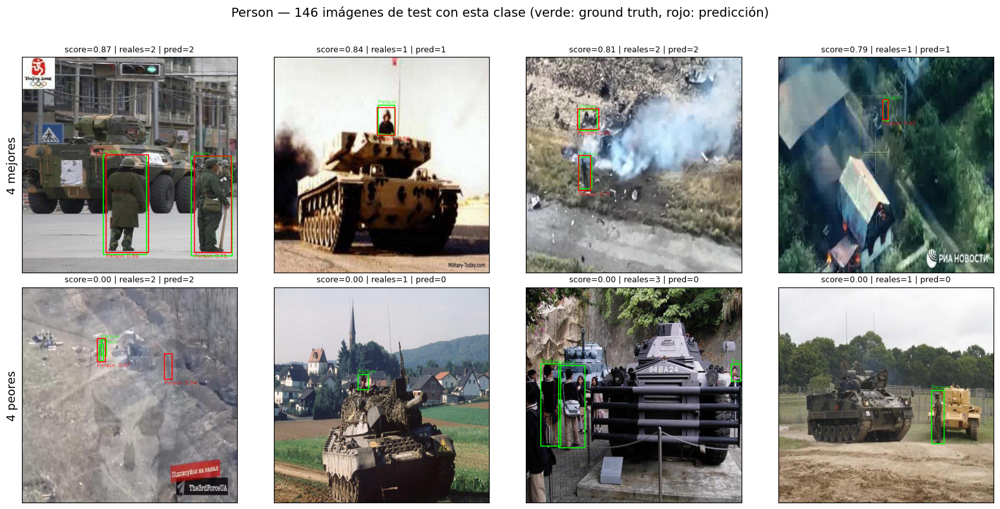

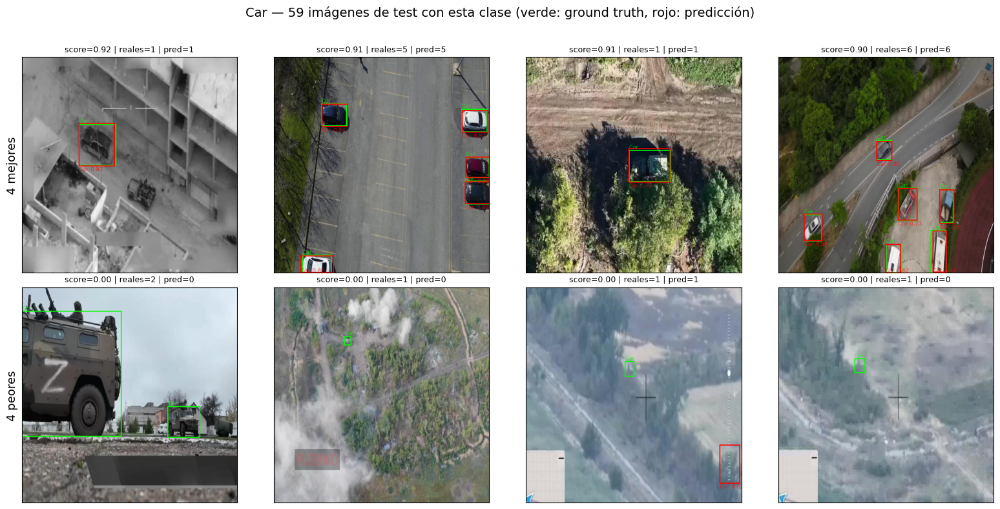

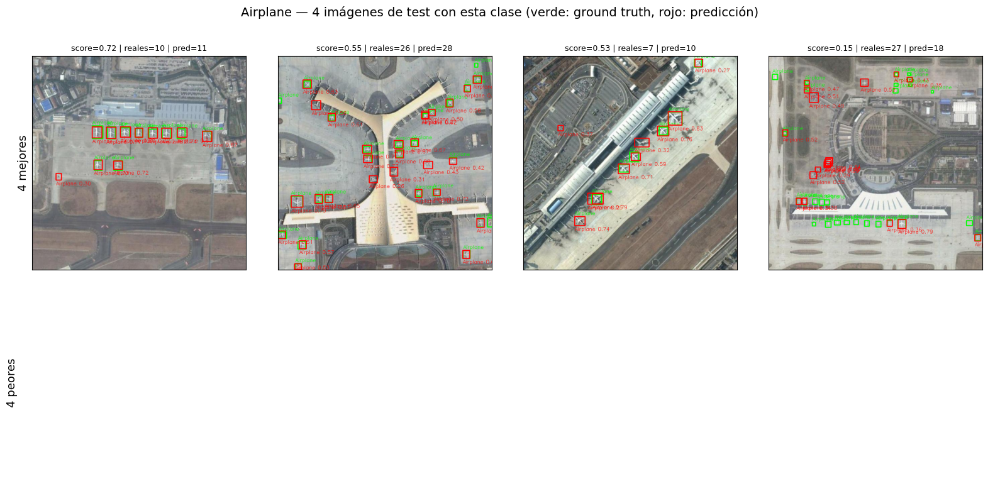

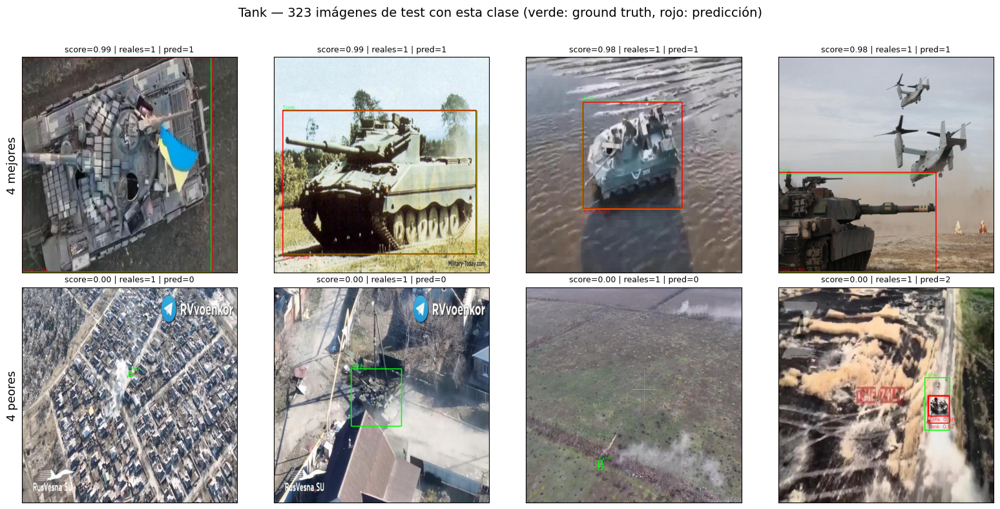

In [ ]:
NUM_EXAMPLES = 4


def draw_prediction_boxes(img, pred_boxes, class_names, color=(255, 0, 0), only_class=None):
    """Dibuja las predicciones (cls_id, conf, x1, y1, x2, y2) sobre la imagen; la etiqueta va debajo de la caja."""
    h = img.shape[0]
    for cls_id, conf, x1, y1, x2, y2 in pred_boxes:
        if only_class is not None and cls_id != only_class:
            continue
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
        cv2.putText(img, f"{class_names[cls_id]} {conf:.2f}", (int(x1), min(int(y2) + 15, h - 2)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    return img


def class_score(res, cls_id):
    n_gt = sum(1 for g in res['gt'] if g[0] == cls_id)
    n_pred = sum(1 for p in res['pred'] if p[0] == cls_id)
    ious = [iou for c, iou in res['matches'] if c == cls_id]
    n_fp = n_pred - len(ious)
    return sum(ious) / (n_gt + n_fp)


for cls_id, name in enumerate(target_classes):
    candidates = [(class_score(res, cls_id), res) for res in per_image_results
                  if any(g[0] == cls_id for g in res['gt'])]
    if not candidates:
        print(f"{name}: no hay imágenes de test con esta clase")
        continue

    ranked = sorted(candidates, key=lambda t: (-t[0], t[1]['path']))
    best = ranked[:NUM_EXAMPLES]
    worst = sorted(ranked[NUM_EXAMPLES:], key=lambda t: (t[0], t[1]['path']))[:NUM_EXAMPLES]

    fig, axes = plt.subplots(2, NUM_EXAMPLES, figsize=(4 * NUM_EXAMPLES, 8), squeeze=False)
    for row, (row_label, examples) in enumerate([('4 mejores', best), ('4 peores', worst)]):
        for j in range(NUM_EXAMPLES):
            ax = axes[row, j]
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(row_label, fontsize=13)
            if j >= len(examples):
                ax.set_frame_on(False)
                continue
            score, res = examples[j]
            img = draw_boxes_on_image(res['path'], res['label_path'], target_classes,
                                      color=(0, 255, 0), only_class=cls_id)
            img = draw_prediction_boxes(img, res['pred'], target_classes, only_class=cls_id)
            ax.imshow(img)
            n_gt = sum(1 for g in res['gt'] if g[0] == cls_id)
            n_pred = sum(1 for p in res['pred'] if p[0] == cls_id)
            ax.set_title(f"score={score:.2f} | reales={n_gt} | pred={n_pred}", fontsize=9)

    fig.suptitle(f"{name} — {len(candidates)} imágenes de test con esta clase "
                 f"(verde: ground truth, rojo: predicción)", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [ ]:
print("=" * 60)
print("REPORTE FINAL")
print("=" * 60)
print(f"Modelo: {MODEL_SIZE} | imgsz={IMG_SIZE} | épocas={EPOCHS}")
print(f"Clases: {target_classes}\n")

print("-- Validación (split 'val') --")
print(f"Precisión media: {val_metrics.box.mp:.4f}")
print(f"Recall medio:    {val_metrics.box.mr:.4f}")
print(f"mAP@50:          {val_metrics.box.map50:.4f}")
print(f"mAP@50-95:       {val_metrics.box.map:.4f}\n")

print("-- Test: solapamiento de cajas (IoU / Dice) --")
print(f"IoU medio:  {mean_iou:.4f}")
print(f"Dice medio: {mean_dice:.4f}")
print(f"Detecciones válidas (IoU >= {IOU_MATCH_THRESHOLD}): {len(matched_ious)} / {n_gt_total} objetos reales")

REPORTE FINAL
Modelo: yolov8n.pt | imgsz=416 | épocas=30
Clases: ['Person', 'Car', 'Airplane', 'Tank']

-- Validación (split 'val') --
Precisión media: 0.8463
Recall medio:    0.6967
mAP@50:          0.7721
mAP@50-95:       0.4720

-- Test: solapamiento de cajas (IoU / Dice) --
IoU medio:  0.8035
Dice medio: 0.8859
Detecciones válidas (IoU >= 0.5): 968 / 1606 objetos reales


## Matriz de confusión (test)

En detección la matriz de confusión no sale directo de comparar una etiqueta por imagen: primero hay que **emparejar cajas**. Para cada imagen de test emparejamos cada caja real con la predicción de mayor IoU (≥ 0.5) **sin mirar la clase**, así podemos ver cuándo el modelo encuentra el objeto pero le asigna la clase equivocada (por ejemplo, un `Tank` predicho como `Car`).

Agregamos una clase extra **Fondo** para los errores que no son de clase:

- **Columna Fondo**: objetos reales que el modelo no detectó (falsos negativos).
- **Fila Fondo**: detecciones que no corresponden a ningún objeto real (falsos positivos).

Usamos las mismas predicciones que en la sección de IoU/Dice (`conf ≥ 0.25`). Como acá el emparejamiento ignora la clase, la cantidad de aciertos puede diferir levemente de la de esa sección.

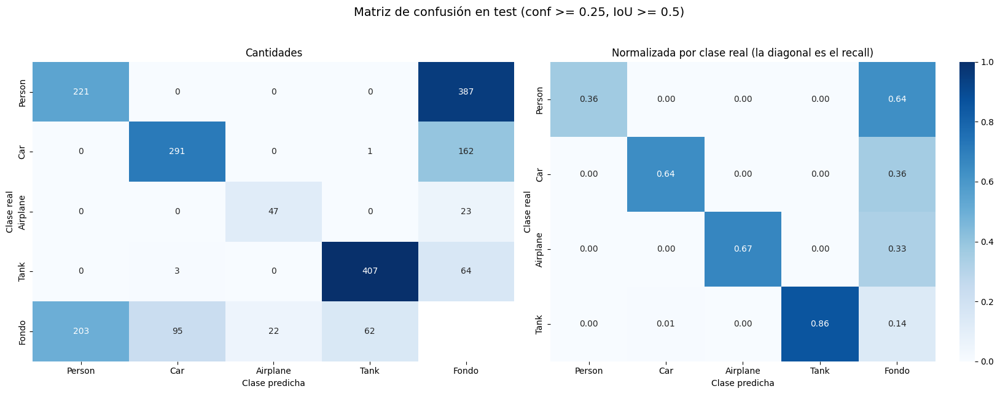

,Reales,Predichas,Aciertos (TP),Confundidos con otra clase,No detectados (FN),Falsos positivos (fondo),Precisión,Recall
Person,608,424,221,0,387,203,0.521,0.363
Car,454,389,291,1,162,95,0.748,0.641
Airplane,70,69,47,0,23,22,0.681,0.671
Tank,474,470,407,3,64,62,0.866,0.859


In [ ]:
# Filas = clase real, columnas = clase predicha; el último índice es "Fondo"
cm_labels = target_classes + ['Fondo']
bg = len(target_classes)
conf_matrix = np.zeros((bg + 1, bg + 1), dtype=int)

for res in per_image_results:
    gt_boxes, pred_boxes = res['gt'], res['pred']

    # Todos los pares (real, predicción) con IoU suficiente, sin importar la clase
    pairs = []
    for gi, (_, *gbox) in enumerate(gt_boxes):
        for pi, (_, _, *pbox) in enumerate(pred_boxes):
            iou = iou_xyxy(pbox, gbox)
            if iou >= IOU_MATCH_THRESHOLD:
                pairs.append((iou, gi, pi))
    pairs.sort(reverse=True)  # emparejamiento greedy: primero los pares con mayor IoU

    gt_used, pred_used = set(), set()
    for iou, gi, pi in pairs:
        if gi in gt_used or pi in pred_used:
            continue
        gt_used.add(gi)
        pred_used.add(pi)
        conf_matrix[gt_boxes[gi][0], pred_boxes[pi][0]] += 1

    for gi, g in enumerate(gt_boxes):
        if gi not in gt_used:
            conf_matrix[g[0], bg] += 1  # objeto real no detectado (FN)
    for pi, p in enumerate(pred_boxes):
        if pi not in pred_used:
            conf_matrix[bg, p[0]] += 1  # detección sin objeto real (FP)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Cantidades absolutas (la celda Fondo/Fondo no está definida)
mask = np.zeros_like(conf_matrix, dtype=bool)
mask[bg, bg] = True
sns.heatmap(conf_matrix, mask=mask, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=cm_labels, yticklabels=cm_labels, ax=axes[0])
axes[0].set_title('Cantidades')

# Normalizada por fila: qué proporción de cada clase real terminó en cada columna
row_sums = conf_matrix[:bg].sum(axis=1, keepdims=True)
cm_norm = conf_matrix[:bg] / np.maximum(row_sums, 1)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=cm_labels, yticklabels=target_classes, ax=axes[1])
axes[1].set_title('Normalizada por clase real (la diagonal es el recall)')

for ax in axes:
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
fig.suptitle(f'Matriz de confusión en test (conf >= {CONF_THRESHOLD}, IoU >= {IOU_MATCH_THRESHOLD})', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Resumen por clase a partir de la matriz
tp = np.diag(conf_matrix)[:bg]
n_real = conf_matrix[:bg].sum(axis=1)
n_pred = conf_matrix[:, :bg].sum(axis=0)
cm_summary = pd.DataFrame({
    'Reales': n_real,
    'Predichas': n_pred,
    'Aciertos (TP)': tp,
    'Confundidos con otra clase': n_real - tp - conf_matrix[:bg, bg],
    'No detectados (FN)': conf_matrix[:bg, bg],
    'Falsos positivos (fondo)': conf_matrix[bg, :bg],
    'Precisión': np.round(tp / np.maximum(n_pred, 1), 3),
    'Recall': np.round(tp / np.maximum(n_real, 1), 3),
}, index=target_classes)
display(cm_summary)

## Conclusión



**Rendimiento general.** El modelo (YOLOv8n, 416px, 30 épocas) alcanzó sobre el set de validación una precisión media de **0.846**, recall de **0.697**, **mAP@50 = 0.772** y **mAP@50-95 = 0.472**. Sobre el set de test, tomando solo las detecciones correctamente emparejadas con su anotación real (IoU ≥ 0.5), el **IoU medio fue 0.804** y el **Dice medio 0.886**.

La brecha grande entre mAP@50 (0.77) y mAP@50-95 (0.47) es consistente con un IoU/Dice de matches altos (0.80 / 0.89): **cuando el modelo detecta un objeto, lo localiza bastante bien** (por eso el Dice es alto), pero pierde bastante precisión a medida que se exige un solapamiento más estricto (0.5→0.95), y además hay una fracción no menor de objetos que directamente no detecta (recall 0.697 en validación; en test, de 1606 objetos reales solo 968 —un 60%— tuvieron una detección emparejada con IoU≥0.5). Es decir: el problema no es tanto "cajas mal dibujadas" sino "objetos no detectados".

Las curvas de entrenamiento muestran que la pérdida de train y de validación siguen bajando juntas hasta la época 30 y el mAP global sigue subiendo levemente: **no hay sobreajuste** y el modelo todavía no terminó de converger.

**Desempeño por clase — un resultado que contradice la hipótesis inicial de desbalance:**

| Clase    | Instancias train | AP50  | AP50-95 | Recall (val) | Detectados en test (IoU≥0.5) | IoU medio (test) | Dice medio (test) |
|----------|------------------:|------:|--------:|-------------:|-----------------------------:|------------------:|--------------------:|
| Tank     | 4714              | 0.950 | 0.698   | 0.911        | 409 / 474 (86%)              | 0.852             | 0.917               |
| Airplane | 3241              | 0.824 | 0.440   | 0.696        | 47 / 70 (67%)                | 0.762             | 0.861               |
| Car      | 2332              | 0.707 | 0.452   | 0.633        | 291 / 454 (64%)              | 0.819             | 0.896               |
| Person   | 5647              | 0.608 | 0.298   | 0.546        | 221 / 608 (36%)              | 0.702             | 0.821               |

`Person` es la clase con **más** instancias de entrenamiento (5647) y sin embargo el **peor** desempeño en todas las métricas: en test solo se detectó correctamente un 36% de las personas. En cambio, `Car`, con **menos de la mitad** de instancias que `Person`, la supera en AP50, AP50-95, recall, IoU y Dice. Esto descarta al desbalance de clases como la causa principal de los errores: lo que más pesa acá es la **dificultad visual intrínseca** de cada clase, no la cantidad de ejemplos vistos.

Las curvas de AP por época refuerzan esto: `Tank` supera AP@50 = 0.8 ya en la época 5 y después casi no mejora, mientras que `Person` y `Car` siguen subiendo hasta la última época. `Person` es además la clase más inestable en las primeras épocas. `Airplane`, en cambio, se estanca en AP@50-95 ≈ 0.42–0.44 en las últimas épocas e incluso baja un poco al final.

**Posibles causas de error (a partir de los ejemplos mejores/peores por clase):**
- `Person`: los aciertos son personas de cuerpo entero, cercanas y bien separadas del fondo. Los peores casos son personas chicas y lejanas, grupos de personas al costado de vehículos, o figuras en tomas aéreas, donde el modelo no predice nada o predice una caja desplazada que no llega a IoU 0.5. Esto afecta tanto a la detección (recall bajo) como a la localización exacta (IoU más bajo, 0.70).
- `Tank`: los aciertos son tanques grandes y cercanos, con una silueta rígida y consistente (score ≈ 0.99), lo que explica que sea la clase más fácil. Todos los peores casos son tomas aéreas de dron donde el tanque ocupa unos pocos píxeles o queda tapado por humo o vegetación.
- `Car`: anda muy bien en vistas cenitales limpias (estacionamientos, rutas), incluso con 5–6 autos por imagen. Falla con autos diminutos en imágenes aéreas borrosas o con humo.
- `Airplane`: tiene buen AP50 (0.824) pero cae fuerte en AP50-95 (0.440, incluso por debajo de `Car`). Son imágenes satelitales de aeropuertos con muchos aviones chicos y juntos, donde las cajas no quedan tan ajustadas. **El resultado en test es poco representativo:** las 70 instancias provienen de apenas **4 imágenes**, por lo que la figura de mejores/peores no tiene suficientes imágenes para la fila de "peores". En la más difícil (27 aviones reales) solo se recuperó una parte, con varios falsos positivos sobre estructuras del aeropuerto.
- El modelo usado es el más chico de la familia YOLOv8 (`yolov8n`), entrenado a baja resolución (416px) y por pocas épocas (30). Esto penaliza justamente a los objetos chicos, que son el denominador común de casi todos los fallos observados.

**Posibles mejoras:**
- Subir a `yolov8s`/`yolov8m` y a `imgsz=640` (o más), que es lo que más debería ayudar con los objetos chicos de las tomas aéreas.
- Entrenar más épocas, ya que las curvas de loss y de AP de `Person` y `Car` todavía no se estabilizaron.
- Reforzar el augmentation orientado a objetos chicos y densos (por ejemplo, escalado y recortes en mosaic) para mejorar `Person`, en vez de asumir que hace falta balancear clases por cantidad de instancias.
- Revisar las anotaciones ambiguas de `Car` (vehículos blindados).
- Conseguir más imágenes de test de `Airplane` para evaluar esa clase con confianza.